# RNA ↔ ATAC translation with scButterfly

A multiome experiment measures expression and chromatin accessibility in the same cell. A *translator* learns that pairing and predicts one modality from the other: accessibility for cells that only have scRNA-seq (`rna2atac`) or expression for cells that only have scATAC-seq (`atac2rna`).

`epione.translate` puts translation methods behind one interface and scores them with the metrics of the scTranslation benchmark (Yang *et al.*, KDD 2026). This notebook covers:

1. paired 10x Multiome PBMCs and the preprocessing the methods expect;
2. training **scButterfly** (Cao *et al.*, *Nat Commun* 2024), a dual-aligned VAE with adversarial discriminators, and translating held-out cells in both directions;
3. benchmarking it against two simple baselines with `epi.translate.benchmark`, which works like scib;
4. the fast mode, and saving and loading a model.

The training cells need PyTorch (`pip install epione[translate]`). A GPU is optional but makes training much faster: about 15 minutes here, versus hours on CPU.

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import epione as epi

sc.settings.verbosity = 0

## Data

10x Genomics' Multiome PBMC 10k sample, in the release used by scGLUE and by the scTranslation benchmark:
- 9,631 cells;
- raw RNA counts and raw ATAC peak counts;
- Seurat-WNN cell types in `obs["cell_type"]`.

`epi.datasets.pbmc10k_multiome` downloads the two h5ad files (about 200 MB) once, checks their sha256 sums and caches them. Set `EPIONE_PBMC10K_DIR` to keep them somewhere other than the pooch cache.

In [2]:
rna, atac = epi.datasets.pbmc10k_multiome(os.environ.get("EPIONE_PBMC10K_DIR"))
rna, atac

(AnnData object with n_obs × n_vars = 9631 × 29095
     obs: 'domain', 'protocol', 'dataset', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'nCount_ATAC', 'nFeature_ATAC', 'nCount_SCT', 'nFeature_SCT', 'SCT.weight', 'ATAC.weight', 'wsnn_res.0.8', 'seurat_clusters', 'sub.cluster', 'cell_type'
     var: 'gene_ids', 'feature_types', 'genome', 'chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand', 'thickStart', 'thickEnd', 'itemRgb', 'blockCount', 'blockSizes', 'blockStarts', 'gene_type', 'gene_name', 'hgnc_id', 'havana_gene', 'tag', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
     uns: 'hvg',
 AnnData object with n_obs × n_vars = 9631 × 107194
     obs: 'domain', 'protocol', 'dataset', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'nCount_ATAC', 'nFeature_ATAC', 'nCount_SCT', 'nFeature_SCT', 'SCT.weight', 'ATAC.weight', 'wsnn_res.0.8', 'seurat_clusters', 'sub.cluster', 'cell_type'
     var: 'feature_types', '

## Preprocessing

`epi.translate.prepare` applies scButterfly's preprocessing.

- **RNA:** library-size normalisation, `log1p`, and the 3,000 most variable genes.
- **ATAC:** binarise, drop peaks open in fewer than 0.5% of cells, TF-IDF, then divide by the global maximum so values lie in [0, 1].

The ATAC steps run on the sparse matrix. Peaks are ordered by chromosome, because scButterfly's ATAC encoder and decoder have one block per chromosome.

In [3]:
rna_p, atac_p = epi.translate.prepare(rna, atac)
print(rna_p.shape, atac_p.shape, f"{len(epi.translate.chrom_blocks(atac_p))} chromosome blocks")

(9631, 3000) (9631, 99272) 32 chromosome blocks


## Split

Hold out a stratified 20% of cells as the test set, and 10% of the rest for early stopping. This is the same recipe and seed as the scTranslation parity runs, which reproduces their fold 0 exactly.

In [4]:
from sklearn.model_selection import StratifiedKFold, train_test_split

y = rna_p.obs["cell_type"].astype(str).to_numpy()
rest, test = next(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(y, y))
train, valid = train_test_split(rest, test_size=0.1, stratify=y[rest], random_state=0)
print(f"train {len(train)}, validation {len(valid)}, test {len(test)}")

train 6933, validation 771, test 1927


## Train scButterfly

scButterfly trains in three phases:
1. pretrain an RNA autoencoder;
2. pretrain an ATAC autoencoder;
3. train a shared latent "translator" together with two discriminators, which push translated embeddings to look like real ones.

Each phase stops early when the validation loss hasn't improved for 50 epochs. One model translates in both directions.

The defaults are the published ones: batch 64, 100 + 100 + 200 epochs at most.

In [5]:
import time

t0 = time.time()
model = epi.translate.fit(rna_p, atac_p, method="scbutterfly",
                          train_idx=train, val_idx=valid, seed=0)
print(model, f"trained in {time.time() - t0:.0f} s")

<ScButterfly scbutterfly: 3000 genes <-> 99272 peaks> trained in 1141 s


The losses are on a log scale. Early in the translator phase the validation loss has one off-scale epoch, more than 100× the median. The right panel's axis is capped below it, and the epoch is annotated:

In [6]:
print("translator validation loss, first 5 epochs:", np.round(model.history["translator_val"][:5], 3))

translator validation loss, first 5 epochs: [2.6700000e-01 2.3094155e+06 7.0300000e-01 2.5100000e-01 2.4900000e-01]


This comes from the training scheme, not from a bug:
- scButterfly scores validation with *sampled* latents (the reparameterisation trick), as the reference implementation does.
- Early in the translator phase, the latent log-variance of some cells is large (about 6, i.e. a standard deviation near 20). The KL weight is still warming up from 0, so this is barely penalised.
- An occasional extreme sample then passes through the unbounded RNA decoder (MSE loss) and gives one huge validation value.

A small instrumented run confirmed this: the log-variance was high in every early epoch, and the spikes were sporadic. The spike doesn't affect training, because training uses the per-batch loss. It also doesn't affect early stopping much, because the best epoch is kept.

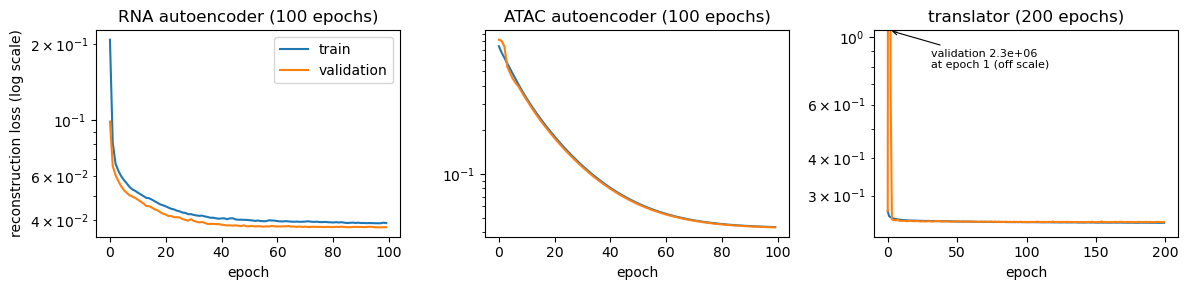

In [7]:
h = model.history
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, key, title in zip(axes, ["rna_pretrain", "atac_pretrain", "translator"],
                          ["RNA autoencoder", "ATAC autoencoder", "translator"]):
    tr_, va_ = np.asarray(h[key]), np.asarray(h[key + "_val"])
    ax.plot(tr_, label="train")
    ax.plot(va_, label="validation")
    ax.set_yscale("log")
    # values more than 100x the median are outliers: cap the axis below them and annotate
    both = np.r_[tr_, va_]
    out = both > 100 * np.median(both)
    if out.any():
        ax.set_ylim(both.min() * 0.9, both[~out].max() * 1.5)
    for e in np.flatnonzero(va_ > 100 * np.median(both)):
        ax.annotate(f"validation {va_[e]:.2g}\nat epoch {e} (off scale)", xy=(e, ax.get_ylim()[1]),
                    xytext=(e + len(va_) * 0.15, ax.get_ylim()[1] * 0.75), fontsize=8,
                    arrowprops=dict(arrowstyle="->", lw=0.8))
    ax.set_title(f"{title} ({len(h[key])} epochs)")
    ax.set_xlabel("epoch")
axes[0].set_ylabel("reconstruction loss (log scale)")
axes[0].legend()
fig.tight_layout()

## Translate held-out cells

`model.predict` takes cells of either modality. The direction is inferred from the features, or can be given explicitly. Predictions keep the input `obs` and carry the target modality's features.

In [8]:
atac_pred = model.predict(rna_p[test])    # RNA -> ATAC
rna_pred = model.predict(atac_p[test])    # ATAC -> RNA
atac_pred, rna_pred

(AnnData object with n_obs × n_vars = 1927 × 99272
     obs: 'domain', 'protocol', 'dataset', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'nCount_ATAC', 'nFeature_ATAC', 'nCount_SCT', 'nFeature_SCT', 'SCT.weight', 'ATAC.weight', 'wsnn_res.0.8', 'seurat_clusters', 'sub.cluster', 'cell_type'
     uns: 'translate',
 AnnData object with n_obs × n_vars = 1927 × 3000
     obs: 'domain', 'protocol', 'dataset', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'nCount_ATAC', 'nFeature_ATAC', 'nCount_SCT', 'nFeature_SCT', 'SCT.weight', 'ATAC.weight', 'wsnn_res.0.8', 'seurat_clusters', 'sub.cluster', 'cell_type'
     uns: 'translate')

Predicted accessibility should separate the cell types the way measured accessibility does. Below is a UMAP of the test cells, from measured and from predicted ATAC.

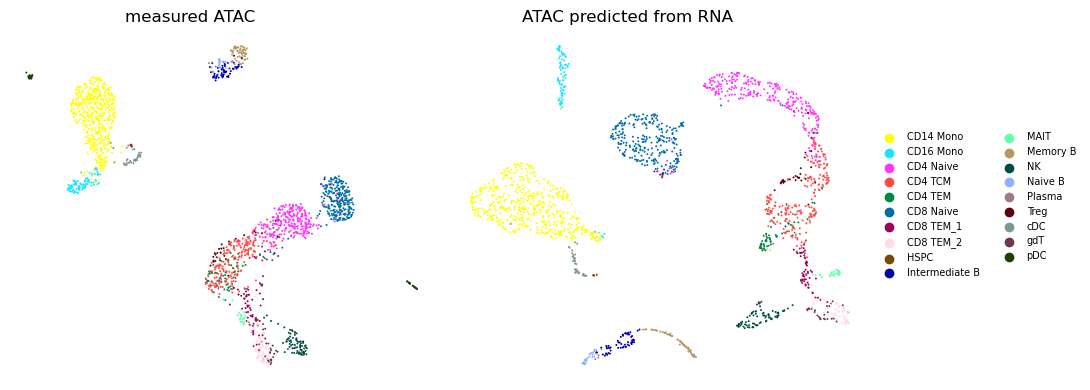

In [9]:
cell_types = sorted(rna_p.obs["cell_type"].astype(str).unique())
palette = dict(zip(cell_types, sc.pl.palettes.default_102[:len(cell_types)]))

def umap_of(ad, title, ax, legend=False):
    a = sc.AnnData(ad.X.toarray() if hasattr(ad.X, "toarray") else ad.X)
    a.obs["cell_type"] = pd.Categorical(ad.obs["cell_type"].astype(str), categories=cell_types)
    sc.pp.pca(a, n_comps=50)
    sc.pp.neighbors(a)
    sc.tl.umap(a, random_state=0)
    sc.pl.umap(a, color="cell_type", palette=palette, ax=ax, show=False, title=title, frameon=False, s=8,
               legend_loc="right margin" if legend else None, legend_fontsize=7)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.35]})
umap_of(atac_p[test], "measured ATAC", axes[0])
umap_of(atac_pred, "ATAC predicted from RNA", axes[1], legend=True)
fig.tight_layout()

The same comparison the other way round: measured expression vs expression predicted from accessibility.

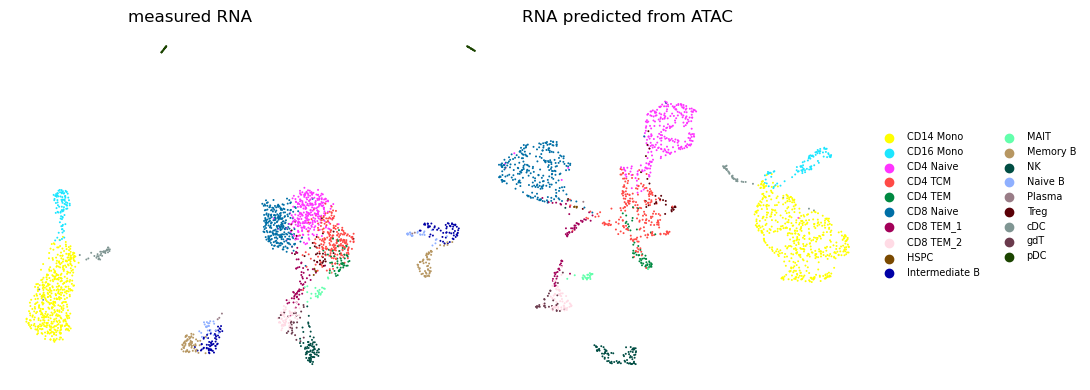

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.35]})
umap_of(rna_p[test], "measured RNA", axes[0])
umap_of(rna_pred, "RNA predicted from ATAC", axes[1], legend=True)
fig.tight_layout()

## Baselines

A benchmark needs reference points. Two simple ones:
- **kNN:** average the target profiles of the 10 training cells nearest in the source modality (50 SVD components);
- **mean:** predict the average training profile for every cell. This is a floor for the per-cell metrics.

In [11]:
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import NearestNeighbors
import scipy.sparse as sp

def knn_translate(src, dst, k=10):
    svd = TruncatedSVD(50, random_state=0).fit(src.X[train])
    nn = NearestNeighbors(n_neighbors=k).fit(svd.transform(src.X[train]))
    idx = nn.kneighbors(svd.transform(src.X[test]), return_distance=False)
    Y = sp.csr_matrix(dst.X[train])
    pred = np.vstack([np.asarray(Y[i].mean(axis=0)).ravel() for i in idx]).astype(np.float32)
    return sc.AnnData(pred, obs=dst.obs.iloc[test].copy(), var=dst.var[[]].copy())

def mean_translate(dst):
    m = np.asarray(sp.csr_matrix(dst.X[train]).mean(axis=0)).astype(np.float32)
    return sc.AnnData(np.repeat(m, len(test), axis=0), obs=dst.obs.iloc[test].copy(), var=dst.var[[]].copy())

base = {
    "rna2atac": {"kNN": knn_translate(rna_p, atac_p), "mean": mean_translate(atac_p)},
    "atac2rna": {"kNN": knn_translate(atac_p, rna_p), "mean": mean_translate(rna_p)},
}

## Fast mode

`fit(..., fast=True)` trains with:
- bf16 autocast;
- batch 256;
- learning rate 2e-3.

It is about 1.7× faster on an H100, but it is **not equivalent** to the default. In the pre-registered check (PBMC 10k, 3 seeds; `tests/parity/translate_scbutterfly/MANIFEST.md`):
- RNA → ATAC accuracy matched the default;
- ATAC → RNA predictions clustered worse (Leiden ARI 0.35 vs 0.45) but correlated better per gene.

It needs more GPU memory and isn't trained here. Use the default when results should be comparable to the reference implementation.

## Benchmark

`epi.translate.benchmark` takes predictions as `{task: {method: AnnData}}` and the measured profiles as `{task: AnnData}`. It returns one tidy row per (task, method, metric). The metrics follow the scTranslation definitions.

| category | metrics |
|---|---|
| clustering | Leiden on the *predicted* profiles vs cell types: ARI, AMI, NMI, homogeneity |
| regression | per-cell Pearson (PCC) and Spearman (SPCC), MSE, MAE; per-feature Pearson (CORR) |
| distribution | MMD between measured and predicted cells; scib's graph iLISI (1 = predicted cells mix perfectly with measured ones) |
| classification | AUROC / AUPRC of the predictions against the measured matrix binarised at its median |

In [12]:
preds = {"rna2atac": {"scButterfly": atac_pred, **base["rna2atac"]},
         "atac2rna": {"scButterfly": rna_pred, **base["atac2rna"]}}
truth = {"rna2atac": atac_p[test], "atac2rna": rna_p[test]}
res = epi.translate.benchmark(preds, truth, labels="cell_type")
res.head()

,task,method,metric,category,higher_is_better,value
0,rna2atac,scButterfly,ARI,clustering,True,0.428545
1,rna2atac,scButterfly,AMI,clustering,True,0.748452
2,rna2atac,scButterfly,NMI,clustering,True,0.758031
3,rna2atac,scButterfly,HOM,clustering,True,0.857713
4,rna2atac,scButterfly,PCC,regression,True,0.309415


`summarize` gives scib-style scores. Each metric is min-max scaled across the methods within a task (flipped where lower is better). The scaled metrics are averaged within each category, and the categories are averaged into an overall score.

In [13]:
summary = epi.translate.summarize(res)
summary.round(3)

metric                                                   \
                        ARI    AMI    NMI    HOM    PCC   SPCC   CORR    MSE   
task     method                                                                
atac2rna scButterfly  0.433  0.743  0.752  0.847  0.764  0.385  0.256  0.037   
         kNN          0.432  0.737  0.748  0.846  0.744  0.394  0.183  0.040   
         mean         0.000  0.004  0.055  0.063  0.634  0.314    NaN  0.055   
rna2atac scButterfly  0.429  0.748  0.758  0.858  0.309  0.346  0.145  0.001   
         kNN          0.446  0.729  0.740  0.823  0.226  0.334  0.082  0.001   
         mean         0.001  0.004  0.045  0.048  0.249  0.321    NaN  0.001   

                                                             score             \
                        MAE    MMD  iLISI  AUROC  AUPRC clustering regression   
task     method                                                                 
atac2rna scButterfly  0.068  0.104  0.528  0.910  0.568      1.000      0.978   
         kNN          0.070  0.074  0.584  0.859  0.515      0.996      0.720   
         mean         0.091  2.390  0.371  0.872  0.369      0.000      0.000   
rna2atac scButterfly  0.013  0.044  0.397  0.892  0.402      0.990      1.000   
         kNN          0.013  0.012  0.636  0.807  0.234      0.977      0.288   
         mean         0.013  1.371  0.222  0.862  0.431      0.000      0.219   

                                                          
                     distribution classification overall  
task     method                                           
atac2rna scButterfly        0.861          1.000   0.960  
         kNN                1.000          0.365   0.770  
         mean               0.000          0.131   0.033  
rna2atac scButterfly        0.700          0.927   0.904  
         kNN                1.000          0.000   0.566  
         mean               0.000          0.826   0.261

In the plots below, each row is a method.
- **Circles:** one per metric. The size and colour show the metric's score min-max scaled across the methods in that task, with 1 (large, yellow) the best; flipped where lower is better (MSE, MAE, MMD). The raw value is printed under the circle.
- **Bars:** to the right of the divider, the category scores and the overall score, which are means of the scaled metrics.

The scaling is relative, so it ranks only the methods shown here.

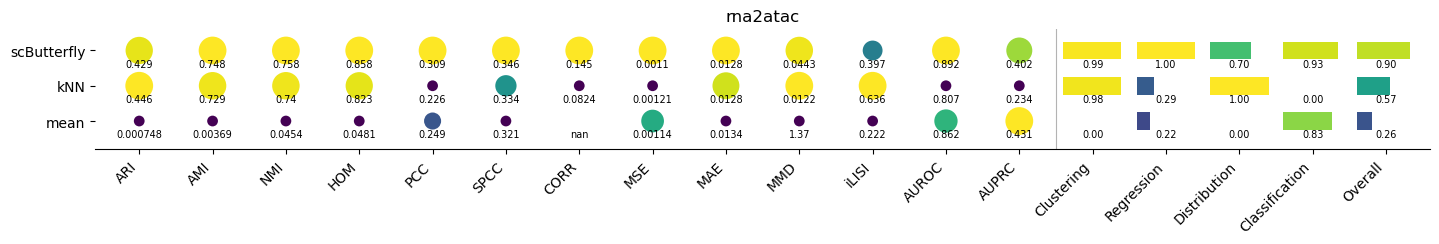

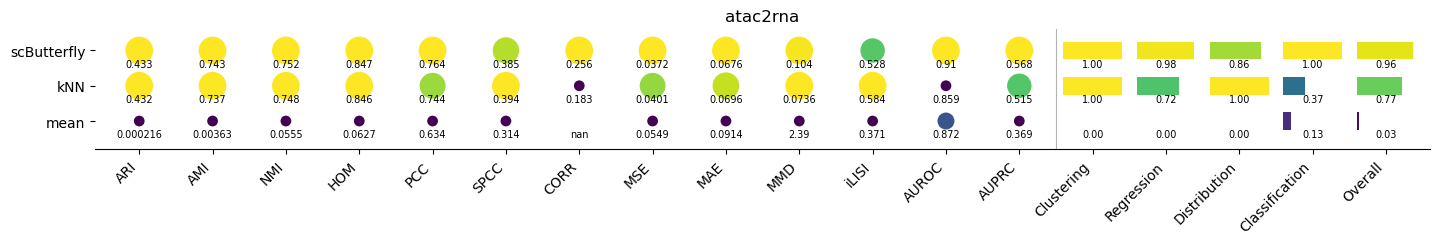

In [14]:
for task in ["rna2atac", "atac2rna"]:
    epi.translate.plot_benchmark(res, task)

Reading the table honestly: scButterfly does not win everywhere.
- **kNN wins the distribution metrics.** The kNN baseline averages *real* profiles of similar training cells, so its predictions look like measured cells. That gives it better distribution scores (MMD, iLISI), and for RNA → ATAC also a slightly higher ARI.
- **scButterfly wins accuracy.** It is clearly ahead on per-cell PCC, per-feature correlation (CORR) and AUROC/AUPRC. Rank correlation (SPCC) is close, and kNN edges it for ATAC → RNA.
- **mean is a floor.** It is the floor for every metric except AUPRC, where pooling over all entries rewards predicting each peak's overall frequency.

The cell below lists every metric where a baseline beats scButterfly in this run.

In [15]:
s = summary["metric"]
for task in ["rna2atac", "atac2rna"]:
    for base_m in ["kNN", "mean"]:
        better = []
        for m in s.columns:
            hib = epi.translate.METRICS[m][1]
            a, b = s.loc[(task, "scButterfly"), m], s.loc[(task, base_m), m]
            if np.isfinite(a) and np.isfinite(b) and (b > a if hib else b < a):
                better.append(f"{m} ({b:.3g} vs {a:.3g})")
        print(f"{task}: {base_m} beats scButterfly on", ", ".join(better) or "nothing")

rna2atac: kNN beats scButterfly on ARI (0.446 vs 0.429), MMD (0.0122 vs 0.0443), iLISI (0.636 vs 0.397)
rna2atac: mean beats scButterfly on AUPRC (0.431 vs 0.402)
atac2rna: kNN beats scButterfly on SPCC (0.394 vs 0.385), MMD (0.0736 vs 0.104), iLISI (0.584 vs 0.528)
atac2rna: mean beats scButterfly on nothing


Accuracy per cell type: the per-cell Pearson correlation of predicted and measured accessibility, with types ordered by their median and labelled with the number of test cells.

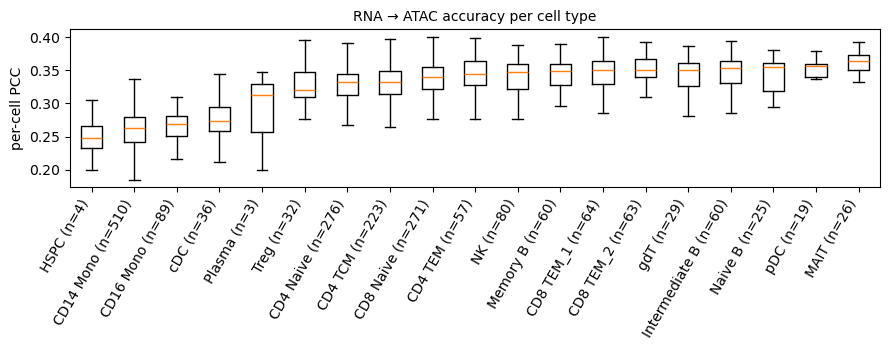

In [16]:
from epione.translate import metrics

pcc = pd.DataFrame({"PCC": metrics.pearson_per_cell(atac_pred, atac_p[test]),
                    "cell_type": atac_p.obs["cell_type"].iloc[test].to_numpy()})
order = pcc.groupby("cell_type")["PCC"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot([pcc.loc[pcc.cell_type == c, "PCC"] for c in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1))
n = pcc["cell_type"].value_counts()
ax.set_xticklabels([f"{c} (n={n[c]})" for c in order], rotation=60, ha="right")
ax.set_ylabel("per-cell PCC")
ax.set_title("RNA → ATAC accuracy per cell type", fontsize=10)
fig.tight_layout()

## Save and load

In [17]:
import tempfile

path = os.path.join(tempfile.mkdtemp(), "scbutterfly_pbmc.pt")
model.save(path)
reloaded = epi.translate.load(path)
np.abs(reloaded.predict(rna_p[test]).X - atac_pred.X).max()

np.float32(0.0)

## Validation against the reference implementation

`epione.translate`'s scButterfly was checked against scTranslation's scButterfly runs on this split, with seeds 0–2 on each side, using gates that were registered before the runs. The protocol and every number are in `tests/parity/translate_scbutterfly/MANIFEST.md`.

Gate results:

| gate | result |
|---|---|
| preprocessing identical to the reference inputs | pass |
| metrics recomputed on the reference predictions reproduce its numbers | pass, to ≤ 1e-4 |
| training parity: 23 metric × direction pairs, \|Δ mean\| ≤ max(2 SD of the reference seeds, floor) | **pass, 23 / 23** |
| fast mode vs default | 1.7× faster; **not** equivalent (ATAC → RNA clustering lower) |

Headline numbers, mean of 3 seeds, reference vs Epione:

| direction | metric | reference | Epione |
|---|---|---|---|
| RNA → ATAC | per-cell PCC | 0.308 | 0.308 |
| ATAC → RNA | per-cell PCC | 0.764 | 0.764 |
| ATAC → RNA | MSE | 0.0372 | 0.0372 |

On the same GPU model, training took 2,500 s for the reference and about 800 s for Epione.

Two things in the reference benchmark differ from its paper and from upstream scButterfly:
- **AUROC and the per-feature correlation have prediction and truth swapped.** `epi.translate.evaluate(..., convention="sctranslation")` reproduces those numbers; the default uses the stated definitions.
- **scTranslation trains scButterfly without shuffling.** Epione shuffles, as upstream does; `shuffle=False` matches the reference. Both settings pass the parity gates.